In [19]:
!pip install rpy2

   ---------------------------------------- 0.0/174.9 kB ? eta -:--:--
   ---------------- ----------------------- 71.7/174.9 kB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 174.9/174.9 kB 2.7 MB/s eta 0:00:00
   ---------------------------------------- 0.0/125.9 kB ? eta -:--:--
   ---------------------------------------- 125.9/125.9 kB 7.2 MB/s eta 0:00:00


In [21]:
import rpy2.robjects as ro
print(ro.r('R.version.string'))

Error importing in API mode: ImportError('On Windows, cffi mode "ANY" is only "ABI".')
Trying to import in ABI mode.


[1] "R version 4.5.0 (2025-04-11 ucrt)"



In [23]:
ro.r('library(limma)')

In [31]:
import rpy2.robjects as ro
import pandas as pd

ro.r('''
    library(limma)
    
    expr <- read.csv("./data/processed/GSE69091_expression_matrix.csv", row.names=1)
    
    group <- factor(c(rep("Control", 3), rep("Notch_ICD", 3)))
    design <- model.matrix(~0 + group)
    colnames(design) <- levels(group)
    
    fit <- lmFit(as.matrix(expr), design)
    contrast.matrix <- makeContrasts(Notch_ICD - Control, levels=design)
    fit2 <- contrasts.fit(fit, contrast.matrix)
    fit2 <- eBayes(fit2, 0.01)
    
    results <- topTable(fit2, adjust="fdr", number=Inf, sort.by="B")
    write.csv(results, "./results/DEG/GSE69091_limma_results.csv")
''')

results_df = pd.read_csv('./results/DEG/GSE69091_limma_results.csv', index_col=0)
print(results_df.shape)
print(results_df.head())

(24647, 6)
            logFC   AveExpr          t       P.Value     adj.P.Val          B
Fmo1     5.544973  8.326880  55.180812  9.271888e-12  2.285242e-07  15.340229
Olfml2a  4.779212  8.206391  48.068461  2.838487e-11  3.498010e-07  14.822786
Lifr     3.646324  8.602595  39.555155  1.376461e-10  9.020074e-07  13.947622
Stom     4.735692  8.885677  38.215204  1.819159e-10  9.020074e-07  13.775257
Hhip     5.183371  7.610555  38.093680  1.866644e-10  9.020074e-07  13.759062


In [33]:
sig_degs = results_df[(results_df['adj.P.Val'] < 0.05) & (abs(results_df['logFC']) >= 1)]
print(f"Total significant DEGs: {len(sig_degs)}")
print(f"Upregulated by Notch: {(sig_degs['logFC'] > 0).sum()}")
print(f"Downregulated by Notch: {(sig_degs['logFC'] < 0).sum()}")

Total significant DEGs: 436
Upregulated by Notch: 342
Downregulated by Notch: 94


In [37]:
sig_degs.to_csv('./results/DEG/GSE69091_DEG_results_strict.csv')
results_df.to_csv('./results/DEG/GSE69091_DEG_results.csv')

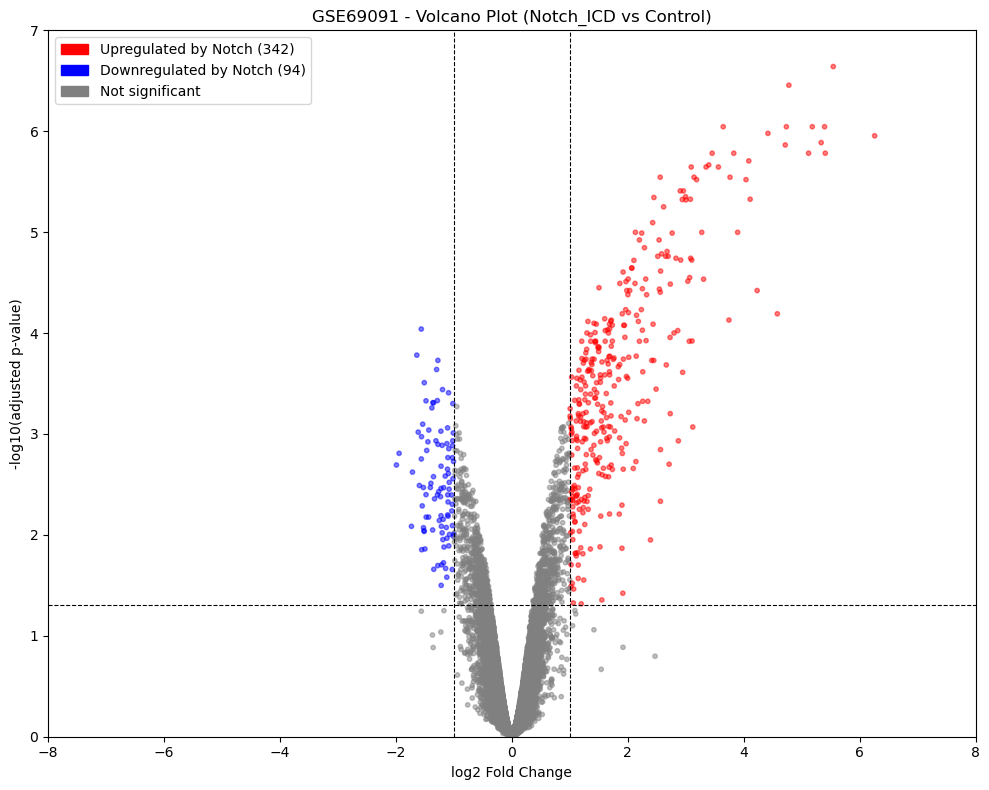

In [43]:
plt.figure(figsize=(10, 8))

colors = []
for idx, row in results_df.iterrows():
    if row['adj.P.Val'] < 0.05 and row['logFC'] >= 1:
        colors.append('red')
    elif row['adj.P.Val'] < 0.05 and row['logFC'] <= -1:
        colors.append('blue')
    else:
        colors.append('grey')

plt.scatter(results_df['logFC'], 
            -np.log10(results_df['adj.P.Val']), 
            c=colors, alpha=0.5, s=10)

plt.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.8)
plt.axvline(1, color='black', linestyle='--', linewidth=0.8)
plt.axvline(-1, color='black', linestyle='--', linewidth=0.8)

plt.xlabel('log2 Fold Change')
plt.ylabel('-log10(adjusted p-value)')
plt.title('GSE69091 - Volcano Plot (Notch_ICD vs Control)')
plt.ylim(0, 7)
plt.xlim(-8, 8)

legend = [Patch(color='red', label=f'Upregulated by Notch ({(sig_degs["logFC"] > 0).sum()})'),
          Patch(color='blue', label=f'Downregulated by Notch ({(sig_degs["logFC"] < 0).sum()})'),
          Patch(color='grey', label='Not significant')]
plt.legend(handles=legend)

plt.tight_layout()
plt.savefig('./figures/GSE69091_volcano.png', dpi=150)
plt.show()